In [1]:
# Initialize Otter
import otter
grader = otter.Notebook("hwk2-task2-salmon.ipynb")

# Task 2: Wrangling Alaska salmon catch data 

## Instructions 

- First, update the following cell to have a link to *your* Homework 2 GitHub repository:


https://github.com/cuvlin/eds220-hwk2.git


- Review the [complete rubric for this task](https://docs.google.com/document/d/1x0BoU6IH4cnOR1-n7i9CYQ9wUC37yDpYlQ4j6rCfcsU/edit?tab=t.0) before starting.

- **Meaningful commits should be made every time you finish a major step.** We'll check your repository and view the commit history.

- **Every code cell should have a comment.** Err on the side of commenting too much for now. Comments should follow best practices.

- **Do not update the top cell with the `otter` import**, this is used internally for grading.

## Acknowledgments

This exercise is based on the [Cleaning and Wrangling Data in R lesson by the NCEAS Learning Hub](https://learning.nceas.ucsb.edu/2023-06-delta/session_11.html).


> Halina Do-Linh, Carmen Galaz García, Matthew B. Jones, Camila Vargas Poulsen. 2023. Open Science Synthesis training Week 1. NCEAS Learning Hub & Delta Stewardship Council.


## About the data

In this task you will use simplified data from the Alaska Department of Fish & Game containing commercial salmon catch data from 1878 to 1997. The original data can be accessed from the KNB repository:

> [Mike Byerly. (2016). Alaska commercial salmon catches by management region (1886-1997).](https://knb.ecoinformatics.org/view/df35b.304.2) Gulf of Alaska Data Portal. df35b.304.2.

The simplified dataset is in CSV format in the homework repository and has the following columns:

| Column | Description |
| ------ | ----------- | 
| Region | Region code |
| Year | Year fish were caught |
| notesRegCode | Notes and comments |
| Species | Species of salmon caught |
| Catch | Commercial catches of salmon species (in thousands of fish) |

## COMPLETE WORKFLOW

You will use the next code cell to complete the last exercise in the task. Leave it blank for now. 

<Axes: title={'center': 'Average Catch Per Region in Alaska from 1878 to 1997'}, xlabel='Region', ylabel='Average Catch (thousands of fish)'>

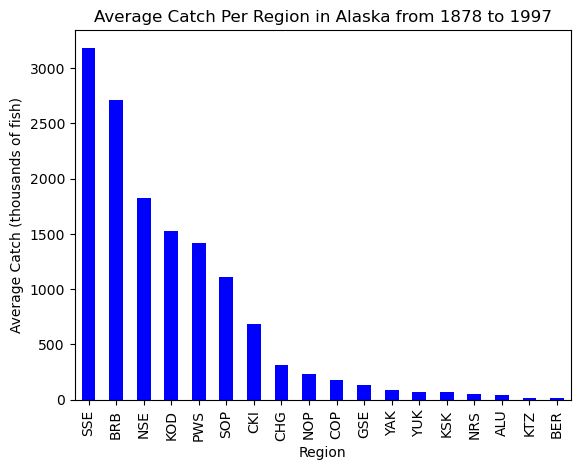

In [24]:
# FINAL CODE

# Load in necessary packages
import pandas as pd
import numpy as np

# Upload salmon_data.csv as catch_data using pd.read_csv()
catch_data = pd.read_csv('/home/calvinfu/eds220/eds220-hwk2/task2/data/salmon_data.csv')

# Drop notesRegCode column using df.drop() method and check upadated dataframe
catch_data = catch_data.drop(columns='notesRegCode')

# Locate the column where catch = I and set the value to 1
catch_data.loc[catch_data['Catch'] == 'I', 'Catch'] = 1

# Update the type of the 'Catch' column to a number type
catch_data['Catch'] = catch_data['Catch'].astype('int64')

# Group by region and find the mean salmon catch for that region (in thousands of fish)
avg_region = catch_data.groupby('Region')['Catch'].mean()

# Plot the average catch per region from 1878 to 1997. Sort from descending order
avg_region.sort_values(ascending=False).plot(
    kind='bar',
    xlabel='Region',
    ylabel='Average Catch (thousands of fish)',
    title='Average Catch Per Region in Alaska from 1878 to 1997',
    color='blue'
)



## 1

a. Use this code cell to import the data from the `salmon_data.csv` as `catch_data`. Look at the head of the data frame. 

<!-- BEGIN QUESTION -->



In [3]:
# Load in necessary packages
import pandas as pd
import numpy as np

# Upload salmon_data.csv as catch_data using pd.read_csv()

catch_data = pd.read_csv('/home/calvinfu/eds220/eds220-hwk2/task2/data/salmon_data.csv')

catch_data.head()


,Region,Year,notesRegCode,Species,Catch
0,SSE,1886,NaN,Chinook,0
1,SSE,1887,NaN,Chinook,0
2,SSE,1888,NaN,Chinook,0
3,SSE,1889,NaN,Chinook,0
4,SSE,1890,NaN,Chinook,0


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

b. Use this code cell to make some other preliminary data exploration of your choosing.

In [4]:
# Check for NA values per columns using .isna().sum() method chain
catch_data.isna().sum()


Region             0
Year               0
notesRegCode    7125
Species            0
Catch              0
dtype: int64

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

c. Use this markdown cell to explain why you decided to do the exploration in b. and what information you obtained from doing it.

I chose to check for the NA values within the dataser because when we chekced the head of the dataframe, the fist 5 valeus of the `notesRegCode` column came up as NA. What this tells us is that 7125 of the reported salmon catch does not have a note attatched to it.

<!-- END QUESTION -->

## 2
In the next cell:

a. Store the unique values of the `notesRegCode` column in the `notes_unique` variable. 

In [5]:
# Store the unique values of the catch notes column as its own variable
notes_unique = catch_data['notesRegCode'].unique()
print(notes_unique)

[nan 'Includes Yakutat catches' 'Yakutat catch included in No SE AK catch'
 'Estimated from canned production, probably sockeye' 'No fishery'
 'Bering River catches included in Copper River catches'
 'Includes Bering River catches; estimated from canned'
 'Includes Bering River catches'
 'Coho and pink catch estimated from canned production'
 'Includes Bering River; coho and pink estimated fro canned'
 'Pink catch estimated from canned'
 'Includes Bering River; coho pink and chum estimated from canned'
 'Includes Bering River; pink estimated from canned'
 'Includes Bering River; pink and chum estimated from canned'
 'Includes Copper River catches'
 'Includes Copper River catches; coho catch porbably mostly pinks'
 'Eshamy District only' 'Estimated from canned; excludes Resurrection Bay'
 'Estimated from canned production' 'No Resurrection Bay fishery'
 'Resurrection bay contribution estimated from canned production'
 'No reported catch' 'Sockeye and pink and 9922 chum from Port Clarenc

In [6]:
grader.check("q2a")

q2a results: All test cases passed!

b. Update the data frame so it doesn't include the `notesRegCode` column. Verify the column is no longer in the data frame.

In [7]:
# Drop notesRegCode column using df.drop() method and check upadated dataframe

catch_data = catch_data.drop(columns='notesRegCode')
print(catch_data.columns)



Index(['Region', 'Year', 'Species', 'Catch'], dtype='object')


In [8]:
grader.check("q2b")

q2b results: All test cases passed!

<!-- BEGIN QUESTION -->

## 3
Does each column have the expected data type? Use this code cell to obtain this information and write your answer in the next markdown cell.


Using the .dtypes() methid were able to check each column to see what type of data is inside of it. The catch column is the data type "object" which usually means strongs. This data is actually supposed to be a number with units of thousands of fish.

In [9]:
# Use .dtypes() method to find the data type of each column
catch_data.dtypes

Region     object
Year        int64
Species    object
Catch      object
dtype: object

<!-- END QUESTION -->

## 4 
The following cell shows a first attempt at updating the `Catch` column to be of data type `int64` instead of `object`. Converting from one data type to another is often called **casting**. 

To do it we use the [`astype()`](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.Series.astype.html) method for `pandas.Series`. The `astype()` method does not modify the `pandas.Series` in place.

Run the next cell and read the end of the error message closely.

In [10]:
catch_data['Catch'].astype('int64')

ValueError: invalid literal for int() with base 10: 'I'

## 5 

The previous error tells us there is a value 'I' (as in the letter 'I') that could not be converted to integer type. It turns out the original data set was created from a PDF which was automatically converted into a CSV file and this 'I' value should be 1.

In the next cell find the row(s) causing this issue. Show the filtered row(s) as the output. Store your answer in the `catch_I` variable. `catch_I` should have one observation and contain the following columns: Region, Year, Species, Catch. It should contain the original index number in order to pass the test. 

In [ ]:
# Locate the row where the 'Catch' is equal to the letter I
catch_I = catch_data[catch_data['Catch'] == 'I']
catch_I


,Region,Year,Species,Catch
400,GSE,1955,Chinook,I


In [ ]:
grader.check("q5")

q5 results: All test cases passed!

## 6
In the next cell:

1. Update the value of I to 1.
2. Access the row you updated to verify the value was changed and store this single row in the `catch_1` variable. 

<!-- BEGIN QUESTION -->



In [11]:

# Locate the column where catch = I and set the value to 1
catch_data.loc[catch_data['Catch'] == 'I', 'Catch'] = 1

# Locate the new for and print it to make sure we assigned a new value. We know the index is 400 from the last part.
catch_1 = catch_data.iloc[400, ]

# Print catch_1
catch_1

Region         GSE
Year          1955
Species    Chinook
Catch            1
Name: 400, dtype: object

<!-- END QUESTION -->

## 7
In the next cell:

1. Update the `Catch` column in `catch_data` to be of type `int64`.
2. Confirm you have updated the data type. Store the type of the `Catch` column in the `catch_column_type` variable.

In [12]:
# Update the type of the 'Catch' column to a number type
catch_data['Catch'] = catch_data['Catch'].astype('int64')

# Confirm the data type of the column
catch_column_type = catch_data.dtypes['Catch']
catch_column_type


dtype('int64')

In [13]:
grader.check("q7")

q7 results: All test cases passed!

<!-- BEGIN QUESTION -->

## 8
Create a data frame with the average salmon catch per region. HINT: use `groupby()`. Store your data frame in a new variable called `avg_region`


In [ ]:
# Group by region and find the mean salmon catch for that region (in thousands of fish)
avg_region = catch_data.groupby('Region')['Catch'].mean()
avg_region

Region
ALU      40.383908
BER      16.372549
BRB    2709.796491
CHG     315.487273
CKI     683.571429
COP     179.223404
GSE     133.841463
KOD    1528.350000
KSK      67.642353
KTZ      18.836145
NOP     229.493478
NRS      51.502703
NSE    1825.020870
PWS    1419.236697
SOP    1110.942222
SSE    3184.660714
YAK      91.922917
YUK      68.645570
Name: Catch, dtype: float64

In [16]:
grader.check("q8")

q8 results: All test cases passed!

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

## 9 

Use the data frame you created in 8 to make a bar graph of the estimated average salmon catches by region from 1878 to 1997. The bars in the graph should be ordered by magnitude (increasing or decreasing is ok). Add a title to your graph and update the axes labels if needed (check the units for the salmon catch). 

<Axes: title={'center': 'Average Catch Per Region in Alaska from 1878 to 1997'}, xlabel='Region', ylabel='Average Catch (thousands of fish)'>

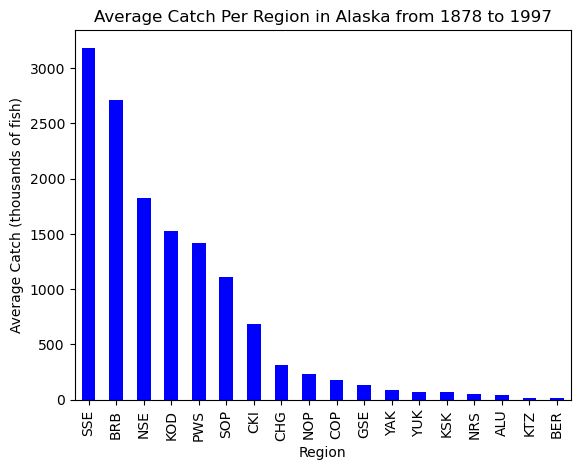

In [23]:
# Plot the average catch per region from 1878 to 1997. Sort from descending order
avg_region.sort_values(ascending=False).plot(
    kind='bar',
    xlabel='Region',
    ylabel='Average Catch (thousands of fish)',
    title='Average Catch Per Region in Alaska from 1878 to 1997',
    color='blue'
)

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

## 10

Write a brief description with key takeaways from the plot. Your answer should use the complete names for the management areas instead of their codes. You can find what each code stands for in the [original data repository](https://knb.ecoinformatics.org/view/df35b.304.2#df35b.303.1).

The five regions in Alaska with the highest catches are Southern South East (SSE), Bristol Bay (BRB), Northern South East (NSE), Kodiak Management Area (KOD), and Prince William Sound Management Area (PWS). If looked at on a map, all five of these areas fall within the southeastern region of Alaska, bordering the Bearing Sea. What this plot shows is that yearly, the south eastern regions of Alaska has significantly more catch than the other regions.

<!-- END QUESTION -->

## 11

Collect all the relevant code into the first blank cell of the notebook titled "COMPLETE WORKFLOW". This single cell will have the end-to-end workflow: from importing libraries and loading the data, to producing the graph. The *only* output of this cell should be the graph you produced in the previous exercise. Further guidance on what to include in this final workflow is in the [assignment rubric](https://docs.google.com/document/d/1x0BoU6IH4cnOR1-n7i9CYQ9wUC37yDpYlQ4j6rCfcsU/edit?tab=t.0).

---

To double-check your work, the cell below will rerun all of the autograder tests.

In [25]:
grader.check_all()

q2a results: All test cases passed!

q2b results: All test cases passed!

q5 results: All test cases passed!

q7 results: All test cases passed!

q8 results: All test cases passed!